# Complete NLP Preprocessing – Twitter Sentiment Dataset

This notebook performs a complete, reproducible NLP preprocessing workflow on the supplied Twitter training dataset.

**Dataset:** `twitter_training.csv`  
**Expected columns:** Tweet ID, Entity, Sentiment, Tweet Text  
**Note:** The source CSV has no header row, so column names are assigned during loading.

## 1. Import required libraries

In [34]:
import re
import string
import unicodedata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download required NLTK resources (safe to rerun)
for resource in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    try:
        nltk.download(resource, quiet=True)
    except Exception as e:
        print(f"Could not download {resource}: {e}")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

In [35]:
# If the CSV is in the same folder as this notebook, this path works.
# Otherwise, change DATA_PATH to the location of your CSV file.
DATA_PATH = "twitter_training.csv"

df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=["tweet_id", "entity", "sentiment", "tweet_text"],
    encoding="utf-8",
    on_bad_lines="skip"
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (74682, 4)


,tweet_id,entity,sentiment,tweet_text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


## 3. Understand the dataset

In [36]:
print("Dataset information:")
df.info()

print("\\nMissing values:")
display(df.isnull().sum().to_frame("missing_count"))

print("\\nSentiment distribution:")
display(df["sentiment"].value_counts(dropna=False).to_frame("count"))

print("\\nDescriptive statistics:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   tweet_id    74682 non-null  int64 
 1   entity      74682 non-null  object
 2   sentiment   74682 non-null  object
 3   tweet_text  73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB
\nMissing values:


,missing_count
tweet_id,0
entity,0
sentiment,0
tweet_text,686


\nSentiment distribution:


,count
sentiment,
Negative,22542
Positive,20832
Neutral,18318
Irrelevant,12990


\nDescriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
tweet_id,74682.0,NaN,NaN,NaN,6432.586165,3740.42787,1.0,3195.0,6422.0,9601.0,13200.0
entity,74682,32,Microsoft,2400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sentiment,74682,4,Negative,22542,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tweet_text,73996,69491,"At the same time, despite the fact that there ...",172,NaN,NaN,NaN,NaN,NaN,NaN,NaN


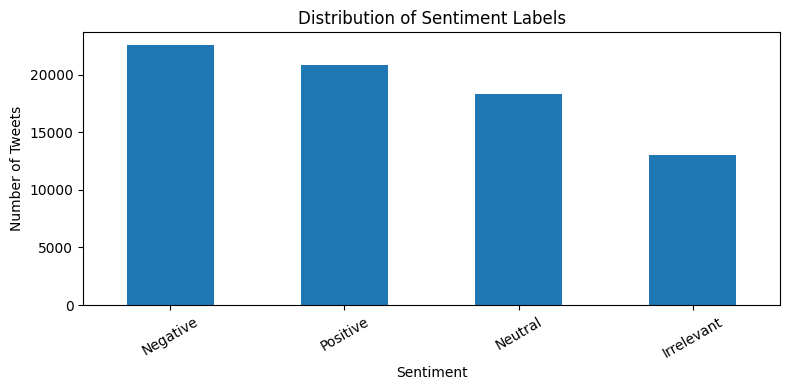

In [37]:
df["sentiment"].value_counts().plot(kind="bar", figsize=(8, 4))
plt.title("Distribution of Sentiment Labels")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. Handle missing values

Rows without tweet text cannot be used for text preprocessing, so they are removed. Missing entity and sentiment values are also removed because they are useful dataset metadata and target labels. The original text is retained in `tweet_text`.

In [38]:
before = len(df)
df = df.dropna(subset=["tweet_text", "sentiment"]).copy()

# Remove rows containing empty or whitespace-only tweet text
df["tweet_text"] = df["tweet_text"].astype(str)
df = df[df["tweet_text"].str.strip().ne("")].copy()

print("Rows before:", before)
print("Rows after missing/empty text removal:", len(df))
print("Rows removed:", before - len(df))

Rows before: 74682
Rows after missing/empty text removal: 73824
Rows removed: 858


## 5. Remove duplicate records

In [39]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", before - len(df))
print("Current shape:", df.shape)

Duplicate rows removed: 2340
Current shape: (71484, 4)


## 6. Standardize sentiment labels

In [40]:
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.title()
print(df["sentiment"].value_counts())

sentiment
Negative      21652
Positive      19677
Neutral       17651
Irrelevant    12504
Name: count, dtype: int64


## 7. Text cleaning and normalization

The cleaning function performs the following operations in a consistent order:

- Decode HTML entities and remove HTML tags.
- Normalize Unicode characters.
- Convert text to lowercase.
- Remove URLs.
- Remove email addresses.
- Remove Twitter usernames/mentions.
- Remove the `#` symbol while preserving hashtag words.
- Expand common English contractions.
- Remove numbers, punctuation, and special characters.
- Normalize repeated whitespace.

This creates `clean_text`. The original tweet remains unchanged in `tweet_text`.

In [41]:
contractions = {
    "can't": "cannot", "won't": "will not", "n't": " not",
    "'re": " are", "'ve": " have", "'ll": " will",
    "'d": " would", "'m": " am", "'s": " is"
}

def expand_contractions(text):
    text = text.lower()
    for contraction, expansion in contractions.items():
        text = text.replace(contraction, expansion)
    return text

def clean_tweet(text):
    text = str(text)
    text = re.sub(r"<[^>]+>", " ", text)               # Remove HTML tags
    text = unicodedata.normalize("NFKC", text)         # Unicode normalization
    text = text.lower()                                # Lowercase
    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text)  # URLs
    text = re.sub(r"\\b[\\w.+-]+@[\\w.-]+\\.[a-zA-Z]{2,}\\b", " ", text) # Emails
    text = re.sub(r"@\\w+", " ", text)                # Mentions
    text = re.sub(r"#(\\w+)", r"\\1", text)          # Keep hashtag word
    text = expand_contractions(text)                   # Contractions
    text = re.sub(r"\\d+", " ", text)                 # Numbers
    text = re.sub(r"[^a-zA-Z\\s]", " ", text)          # Punctuation/special chars
    text = re.sub(r"\\s+", " ", text).strip()         # Extra whitespace
    return text

df["clean_text"] = df["tweet_text"].apply(clean_tweet)
display(df[["tweet_text", "clean_text"]].head(10))

,tweet_text,clean_text
0,im getting on borderlands and i will murder yo...,im getting on borderlands and i will murder yo...
1,I am coming to the borders and I will kill you...,i am coming to the borders and i will kill you...
2,im getting on borderlands and i will kill you ...,im getting on borderlands and i will kill you all
3,im coming on borderlands and i will murder you...,im coming on borderlands and i will murder you...
4,im getting on borderlands 2 and i will murder ...,im getting on borderlands and i will murder ...
5,im getting into borderlands and i can murder y...,im getting into borderlands and i can murder y...
6,So I spent a few hours making something for fu...,so i spent a few hours making something for fu...
7,So I spent a couple of hours doing something f...,so i spent a couple of hours doing something f...
8,So I spent a few hours doing something for fun...,so i spent a few hours doing something for fun...
9,So I spent a few hours making something for fu...,so i spent a few hours making something for fu...


## 8. Tokenization

Tokenization splits each cleaned tweet into individual word tokens.

In [42]:
def tokenize_text(text):
    try:
        return word_tokenize(text)
    except LookupError:
        # Fallback tokenizer if the NLTK punkt resource is unavailable
        return re.findall(r"[a-z]+", text)

df["tokens"] = df["clean_text"].apply(tokenize_text)
display(df[["clean_text", "tokens"]].head())

,clean_text,tokens
0,im getting on borderlands and i will murder yo...,"[im, getting, on, borderlands, and, i, will, m..."
1,i am coming to the borders and i will kill you...,"[i, am, coming, to, the, borders, and, i, will..."
2,im getting on borderlands and i will kill you all,"[im, getting, on, borderlands, and, i, will, k..."
3,im coming on borderlands and i will murder you...,"[im, coming, on, borderlands, and, i, will, mu..."
4,im getting on borderlands and i will murder ...,"[im, getting, on, borderlands, and, i, will, m..."


## 9. Stopword removal

Stopwords are common words such as *the*, *is*, and *and*. They are often removed to reduce noise. For sentiment analysis, negation words such as **no**, **not**, and **never** are deliberately retained because they can change sentiment meaning.

In [43]:
stop_words = set(stopwords.words("english"))
negation_words = {"no", "nor", "not", "never"}
stop_words = stop_words - negation_words

def remove_stopwords(tokens):
    return [word for word in tokens if word not in stop_words and len(word) > 1]

df["tokens_no_stopwords"] = df["tokens"].apply(remove_stopwords)
display(df[["tokens", "tokens_no_stopwords"]].head())

,tokens,tokens_no_stopwords
0,"[im, getting, on, borderlands, and, i, will, m...","[im, getting, borderlands, murder]"
1,"[i, am, coming, to, the, borders, and, i, will...","[coming, borders, kill]"
2,"[im, getting, on, borderlands, and, i, will, k...","[im, getting, borderlands, kill]"
3,"[im, coming, on, borderlands, and, i, will, mu...","[im, coming, borderlands, murder]"
4,"[im, getting, on, borderlands, and, i, will, m...","[im, getting, borderlands, murder]"


## 13. Check final dataset

In [44]:
print("Final dataset shape:", df.shape)
print("\\nMissing values in processed columns:")
display(df[["clean_text", "tokens"]].isnull().sum())

print("\\nSentiment distribution after preprocessing:")
display(df["sentiment"].value_counts())

Final dataset shape: (71484, 7)
\nMissing values in processed columns:


,0
clean_text,0
tokens,0


\nSentiment distribution after preprocessing:


,count
sentiment,
Negative,21652
Positive,19677
Neutral,17651
Irrelevant,12504


## 14. Save the preprocessed dataset

The final CSV includes the original metadata and text, along with each intermediate preprocessing output. Lists of tokens are converted to space-separated strings so the CSV is easy to open in spreadsheet software and reload in Python.

In [45]:
output_df = df.copy()

list_columns = [
    "tokens", "tokens_no_stopwords"
]
for col in list_columns:
    output_df[col] = output_df[col].apply(lambda x: " ".join(x) if isinstance(x, list) else x)

OUTPUT_PATH = "twitter_training_preprocessed.csv"
output_df.to_csv(OUTPUT_PATH, index=False, encoding="utf-8")

print(f"Preprocessed dataset saved to: {OUTPUT_PATH}")
print("Final exported shape:", output_df.shape)

Preprocessed dataset saved to: twitter_training_preprocessed.csv
Final exported shape: (71484, 7)
